# 01 · Dados: inspeção, limpeza e preparação

Este notebook baixa as bases originais, verifica a qualidade, corrige os problemas encontrados, faz o split e a normalização, e salva tudo em `data/processed/`. **Todos os outros notebooks leem dessa pasta.**

Saídas: `data/processed/{ETTh1,Weather}.csv` (colunas `date`, `OT`, `y`, `imputado`, `suspeito`) e `{base}_meta.json`.

In [1]:
# Configuração: igual em todos os notebooks
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJETO = '/content/drive/MyDrive/RN-Projeto'
except ImportError:          # fora do Colab (ex.: rodando no computador)
    PROJETO = os.path.abspath('.')
sys.path.insert(0, os.path.join(PROJETO, 'src'))
print('Pasta do projeto:', PROJETO)

Mounted at /content/drive
Pasta do projeto: /content/drive/MyDrive/RN-Projeto


In [2]:
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

FONTES = {   # fontes oficiais: autores do ETDataset e thuml (autores do Autoformer/Time-Series-Library)
    'ETTh1':   'https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv',
    'Weather': 'https://huggingface.co/datasets/thuml/Time-Series-Library/resolve/main/weather/weather.csv',
}
ARQUIVO = {'ETTh1': 'ETTh1.csv', 'Weather': 'weather.csv'}
PASSO = {'ETTh1': pd.Timedelta('1h'), 'Weather': pd.Timedelta('10min')}
PERIODO = {'ETTh1': 24, 'Weather': 144}          # passos em 1 dia
ALVO = 'OT'                                       # ETTh1: temperatura do óleo · Weather: CO2 (ppm)

for p in ['data/raw', 'data/processed', 'figuras']:
    os.makedirs(os.path.join(PROJETO, p), exist_ok=True)
for ds, url in FONTES.items():
    destino = os.path.join(PROJETO, 'data', 'raw', ARQUIVO[ds])
    if not os.path.exists(destino):
        print('baixando', ds, '...')
        urllib.request.urlretrieve(url, destino)
    print(f'{ds}: {os.path.getsize(destino) / 1e6:.1f} MB')

ETTh1: 2.6 MB
Weather: 7.2 MB


## 1. Inspeção

Verificamos: valores faltando, datas duplicadas, intervalos irregulares, valores sentinela (`-9999`, usado pela estação meteorológica para "sem medição") e trechos em que o alvo fica **exatamente** constante por 12 h ou mais (sinal de dado preenchido artificialmente).

In [3]:
def ler(ds):
    df = pd.read_csv(os.path.join(PROJETO, 'data', 'raw', ARQUIVO[ds]), encoding='latin-1')
    df['date'] = pd.to_datetime(df['date'])
    return df

def trechos_constantes(s, min_passos):
    """Máscara dos pontos que estão em um trecho constante com pelo menos min_passos."""
    grupo = (s.diff() != 0).cumsum()
    return s.groupby(grupo).transform('size') >= min_passos

def inspecionar(ds, df):
    dif = df['date'].diff().dropna()
    sent = (df.drop(columns='date') <= -9990).sum()
    plano = trechos_constantes(df[ALVO], PERIODO[ds] // 2)
    print(f'===== {ds}: {len(df)} linhas, {df.date.min()} → {df.date.max()}, {df.shape[1] - 1} variáveis')
    print('  valores faltando (NaN):      ', int(df.isna().sum().sum()))
    print('  datas duplicadas:            ', int(df['date'].duplicated().sum()),
          '| linhas idênticas:', int(df.duplicated().sum()))
    print('  intervalos fora do padrão:   ', {str(k): v for k, v in dif[dif != PASSO[ds]].value_counts().items()} or 'nenhum')
    print('  sentinelas -9999 por coluna: ', sent[sent > 0].to_dict() or 'nenhum')
    print(f'  {ALVO} constante por ≥ 12 h:  {int(plano.sum())} pontos')

brutos = {ds: ler(ds) for ds in FONTES}
for ds, df in brutos.items():
    inspecionar(ds, df)

===== ETTh1: 17420 linhas, 2016-07-01 00:00:00 → 2018-06-26 19:00:00, 7 variáveis
  valores faltando (NaN):       0
  datas duplicadas:             0 | linhas idênticas: 0
  intervalos fora do padrão:    nenhum
  sentinelas -9999 por coluna:  nenhum
  OT constante por ≥ 12 h:  336 pontos
===== Weather: 52696 linhas, 2020-01-01 00:10:00 → 2021-01-01 00:00:00, 21 variáveis
  valores faltando (NaN):       0
  datas duplicadas:             1 | linhas idênticas: 1
  intervalos fora do padrão:    {'0 days 00:00:00': 1, '0 days 01:40:00': 1}
  sentinelas -9999 por coluna:  {'wv (m/s)': 1, 'max. PAR (ï¿½mol/mï¿½/s)': 30, 'OT': 50}
  OT constante por ≥ 12 h:  0 pontos


### O que aparece

- **Weather**: o alvo `OT` tem 50 valores `-9999`, além de uma linha duplicada e um buraco de 100 min. Também há `-9999` em `wv` e `max. PAR`, que não usamos porque o estudo é univariado.
- **ETTh1**: não há faltantes, mas há dias inteiros constantes. A célula abaixo mostra que são **sempre o dia 31** e que **todas as colunas** ficam constantes nesses dias.

In [4]:
e = brutos['ETTh1']
plano = trechos_constantes(e[ALVO], 12)
inicio = e.loc[plano & ~plano.shift(fill_value=False), 'date']
print('Dias constantes no ETTh1:', len(inicio))
print(inicio.dt.strftime('%Y-%m-%d').tolist())
for c in e.columns[1:]:
    print(f'  {c:5s}: também constante nesses dias? {bool(trechos_constantes(e[c], 12)[plano].all())}')

Dias constantes no ETTh1: 14
['2016-07-31', '2016-08-31', '2016-10-31', '2016-12-31', '2017-01-31', '2017-03-31', '2017-05-31', '2017-07-31', '2017-08-31', '2017-10-31', '2017-12-31', '2018-01-31', '2018-03-31', '2018-05-31']
  HUFL : também constante nesses dias? True
  HULL : também constante nesses dias? True
  MUFL : também constante nesses dias? True
  MULL : também constante nesses dias? True
  LUFL : também constante nesses dias? True
  LULL : também constante nesses dias? True
  OT   : também constante nesses dias? True


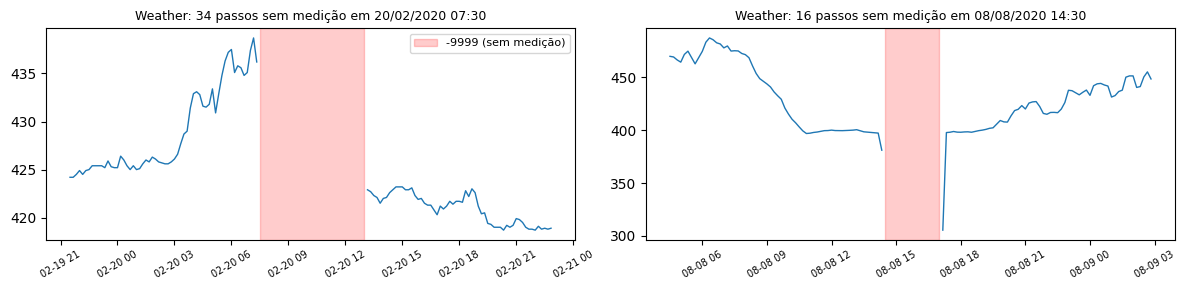

Desvio de OT no Weather COM os -9999: 321.6 | SEM: 18.7


In [5]:
w = brutos['Weather']
ruins = np.where(w[ALVO] <= -9990)[0]
blocos = np.split(ruins, np.where(np.diff(ruins) != 1)[0] + 1)
fig, axs = plt.subplots(1, len(blocos), figsize=(12, 3))
for ax, b in zip(axs, blocos):
    j = slice(b[0] - 60, b[-1] + 60)
    ax.plot(w['date'][j], w[ALVO][j].where(w[ALVO][j] > -9990), lw=1)
    ax.axvspan(w['date'][b[0]], w['date'][b[-1]], color='red', alpha=.2, label='-9999 (sem medição)')
    ax.set_title(f'Weather: {len(b)} passos sem medição em {w["date"][b[0]]:%d/%m/%Y %H:%M}', fontsize=9)
    ax.tick_params(axis='x', labelsize=7, rotation=30)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'Desvio de OT no Weather COM os -9999: {w[ALVO].std():.1f} | SEM: {w[ALVO][w[ALVO] > -9990].std():.1f}')

## 2. Limpeza

| Problema | Tratamento | Justificativa |
|---|---|---|
| Linha duplicada (Weather) | removida | é uma cópia idêntica |
| Buraco de 100 min (Weather) | grade de 10 min completada; valores interpolados | os modelos assumem passos igualmente espaçados |
| `-9999` no alvo (Weather) | trocado por faltante e interpolado linearmente; marcado `imputado` | o sentinela não é medição; mantê-lo distorce a normalização e o treino |
| Leituras vizinhas aos blocos `-9999` | também descartadas e interpoladas | duas delas são 381,1 e 305,5 ppm, implausíveis para CO₂ (o resto da série fica acima de ~390): é o sensor desligando ou religando |
| Amostras com alvo imputado | descartadas do treino e da validação | não queremos ensinar o modelo a prever uma reta que nós inventamos |
| Dias 31 constantes (ETTh1) | mantidos e marcados `suspeito`; métrica extra sem eles | removê-los quebraria a continuidade e a comparação com a literatura |

In [6]:
def limpar(ds, df):
    df = df[['date', ALVO]].copy()
    df = df.drop_duplicates()                                  # linha idêntica
    assert not df['date'].duplicated().any(), 'datas duplicadas com valores diferentes'
    grade = pd.date_range(df['date'].min(), df['date'].max(), freq=PASSO[ds])
    df = df.set_index('date').reindex(grade)                   # completa buracos com NaN
    df.index.name = 'date'
    sentinela = df[ALVO] <= -9990
    # a leitura logo antes e logo depois de cada bloco sem medição também é descartada:
    # no Weather elas são 381,1 e 305,5 ppm, implausíveis para CO2 (sensor desligando/religando)
    borda = (sentinela.shift(1, fill_value=False) | sentinela.shift(-1, fill_value=False)) & ~sentinela
    if borda.any():
        print(f'{ds}: leituras de borda descartadas: {df.loc[borda, ALVO].round(1).tolist()}')
    df.loc[sentinela | borda, ALVO] = np.nan                   # sentinela vira faltante
    df['imputado'] = df[ALVO].isna()
    df[ALVO] = df[ALVO].interpolate(method='time', limit_direction='both')
    df['suspeito'] = trechos_constantes(df[ALVO], PERIODO[ds] // 2) & ~df['imputado']
    return df.reset_index()

limpos = {ds: limpar(ds, df) for ds, df in brutos.items()}
for ds, df in limpos.items():
    print(f'{ds}: {len(df)} passos | imputados: {int(df.imputado.sum())} | suspeitos: {int(df.suspeito.sum())} '
          f'| faltantes restantes: {int(df[ALVO].isna().sum())}')

Weather: leituras de borda descartadas: [436.2, 422.9, 381.1, 305.5]
ETTh1: 17420 passos | imputados: 0 | suspeitos: 336 | faltantes restantes: 0
Weather: 52704 passos | imputados: 63 | suspeitos: 0 | faltantes restantes: 0


## 3. Split e normalização

- **ETTh1**: 12 / 4 / 4 meses (padrão). O restante da série (após 20 meses) não é usado, como nos artigos.
- **Weather**: 70 / 10 / 20 %.
- z-score com média e desvio **do treino** (sem os pontos imputados).

In [7]:
def limites(ds, n):
    if ds == 'ETTh1':
        m = 30 * 24
        return 12 * m, 16 * m, 20 * m
    n_tr, n_te = int(n * 0.7), int(n * 0.2)
    return n_tr, n - n_te, n

for ds, df in limpos.items():
    fim_tr, fim_va, fim_te = limites(ds, len(df))
    df = df.iloc[:fim_te].copy()
    treino = df.iloc[:fim_tr]
    media = float(treino.loc[~treino.imputado, ALVO].mean())
    desvio = float(treino.loc[~treino.imputado, ALVO].std())
    df['y'] = (df[ALVO] - media) / desvio
    meta = {'base': ds, 'alvo': ALVO, 'n': len(df), 'fim_treino': fim_tr, 'fim_val': fim_va, 'fim_teste': fim_te,
            'media_treino': media, 'desvio_treino': desvio, 'periodo': PERIODO[ds],
            'inicio': str(df.date.iloc[0]), 'fim': str(df.date.iloc[-1]),
            'datas_split': [str(df.date.iloc[i]) for i in (0, fim_tr, fim_va, fim_te - 1)],
            'imputados_por_split': [int(df.imputado.iloc[a:b].sum()) for a, b in ((0, fim_tr), (fim_tr, fim_va), (fim_va, fim_te))],
            'suspeitos_por_split': [int(df.suspeito.iloc[a:b].sum()) for a, b in ((0, fim_tr), (fim_tr, fim_va), (fim_va, fim_te))]}
    df[['date', ALVO, 'y', 'imputado', 'suspeito']].to_csv(
        os.path.join(PROJETO, 'data', 'processed', f'{ds}.csv'), index=False, float_format='%.6f')
    with open(os.path.join(PROJETO, 'data', 'processed', f'{ds}_meta.json'), 'w', encoding='utf-8') as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)
    limpos[ds] = df
    print(f'{ds}: treino {fim_tr} | val {fim_va - fim_tr} | teste {fim_te - fim_va} passos | '
          f'média {media:.3f} desvio {desvio:.3f} | imputados (tr/val/te) {meta["imputados_por_split"]} '
          f'| suspeitos {meta["suspeitos_por_split"]}')

ETTh1: treino 8640 | val 2880 | teste 2880 passos | média 17.128 desvio 9.177 | imputados (tr/val/te) [0, 0, 0] | suspeitos [168, 48, 72]
Weather: treino 36892 | val 5272 | teste 10540 passos | média 425.186 desvio 18.170 | imputados (tr/val/te) [63, 0, 0] | suspeitos [0, 0, 0]


## 4. Visualização da série e da sazonalidade

A autocorrelação no treino mostra o pico em 1 dia (24 passos no ETTh1, 144 no Weather). É isso que justifica o período do **seasonal naive**.

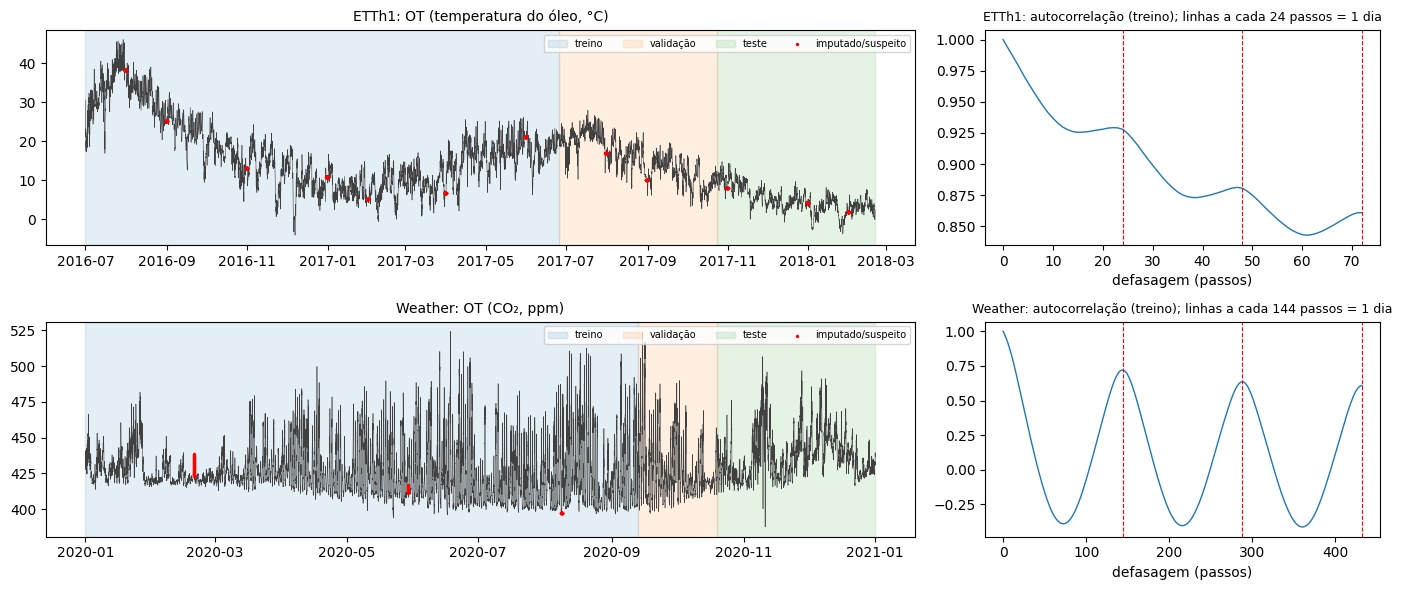

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [2.2, 1]})
for i, (ds, df) in enumerate(limpos.items()):
    with open(os.path.join(PROJETO, 'data', 'processed', f'{ds}_meta.json'), encoding='utf-8') as f:
        m = json.load(f)
    ax = axs[i, 0]
    ax.plot(df['date'], df[ALVO], lw=.4, color='0.25')
    for (a, b), cor, nome in zip(((0, m['fim_treino']), (m['fim_treino'], m['fim_val']), (m['fim_val'], m['fim_teste'] - 1)),
                                 ('tab:blue', 'tab:orange', 'tab:green'), ('treino', 'validação', 'teste')):
        ax.axvspan(df['date'].iloc[a], df['date'].iloc[b], color=cor, alpha=.12, label=nome)
    marc = df[df.imputado | df.suspeito]
    ax.scatter(marc['date'], marc[ALVO], s=2, color='red', label='imputado/suspeito', zorder=3)
    ax.set_title(f'{ds}: {ALVO} ({"temperatura do óleo, °C" if ds == "ETTh1" else "CO₂, ppm"})', fontsize=10)
    ax.legend(fontsize=7, ncol=4, loc='upper right')
    treino_y = df['y'].iloc[:m['fim_treino']]
    P = m['periodo']
    r = acf(treino_y, nlags=3 * P, fft=True)
    ax = axs[i, 1]
    ax.plot(np.arange(len(r)), r, lw=1)
    for k in (1, 2, 3):
        ax.axvline(k * P, color='red', ls='--', lw=.8)
    ax.set_title(f'{ds}: autocorrelação (treino); linhas a cada {P} passos = 1 dia', fontsize=9)
    ax.set_xlabel('defasagem (passos)')
plt.tight_layout()
plt.savefig(os.path.join(PROJETO, 'figuras', 'dados_series_e_acf.png'), dpi=150)
plt.show()

## 5. Conferência final

In [9]:
for ds in limpos:
    d = pd.read_csv(os.path.join(PROJETO, 'data', 'processed', f'{ds}.csv'), parse_dates=['date'])
    with open(os.path.join(PROJETO, 'data', 'processed', f'{ds}_meta.json'), encoding='utf-8') as f:
        m = json.load(f)
    assert d['y'].notna().all(), 'ainda há faltantes'
    assert (d['date'].diff().dropna() == PASSO[ds]).all(), 'grade irregular'
    assert d.imputado.iloc[m['fim_val']:].sum() == 0, 'há pontos imputados no teste'
    tr = d['y'].iloc[:m['fim_treino']][~d.imputado.iloc[:m['fim_treino']]]
    print(f'{ds}: OK | {len(d)} passos | split em {m["datas_split"]} | treino normalizado: média {tr.mean():+.3f}, desvio {tr.std():.3f}')

ETTh1: OK | 14400 passos | split em ['2016-07-01 00:00:00', '2017-06-26 00:00:00', '2017-10-24 00:00:00', '2018-02-20 23:00:00'] | treino normalizado: média -0.000, desvio 1.000
Weather: OK | 52704 passos | split em ['2020-01-01 00:10:00', '2020-09-13 04:50:00', '2020-10-19 19:30:00', '2021-01-01 00:00:00'] | treino normalizado: média +0.000, desvio 1.000
